In [154]:
import pandas as pd
from pytrends.request import TrendReq
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [155]:
pytrend = TrendReq(hl = 'en-US',tz = 360 , timeout=(10 , 25))
keywords = ['Python' , 'Java' , 'JavaScript']

In [156]:
pytrend.build_payload(kw_list=keywords,timeframe = 'today 12-m',geo = 'IN')

In [157]:
df_tech = pytrend.interest_over_time()
print(df_tech.head(10))
print(df_tech.info())

            Python  Java  JavaScript  isPartial
date                                           
2025-11-09      89    71          14      False
2025-11-16      87    64          13      False
2025-11-23      84    64          13      False
2025-11-30      89    63          14      False
2025-12-07      90    67          14      False
2025-12-14      82    61          12      False
2025-12-21      67    51          10      False
2025-12-28      65    51          10      False
2026-01-04      81    61          12      False
2026-01-11      68    51           9      False
<class 'pandas.DataFrame'>
DatetimeIndex: 53 entries, 2025-11-09 to 2026-11-08
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Python      53 non-null     int64
 1   Java        53 non-null     int64
 2   JavaScript  53 non-null     int64
 3   isPartial   53 non-null     bool 
dtypes: bool(1), int64(3)
memory usage: 1.7 KB
None


In [158]:
anime_keywords = ['Naruto' , 'One Piece' , 'Demon Slayer']
pytrend.build_payload(kw_list=anime_keywords , timeframe='today 12-m' , geo = 'IN')
df_anime = pytrend.interest_over_time()

In [159]:
df_anime.head()

,Naruto,One Piece,Demon Slayer,isPartial
date,,,,
2025-11-09,51,33,31,False
2025-11-16,53,35,31,False
2025-11-23,50,39,30,False
2025-11-30,46,38,26,False
2025-12-07,49,42,27,False


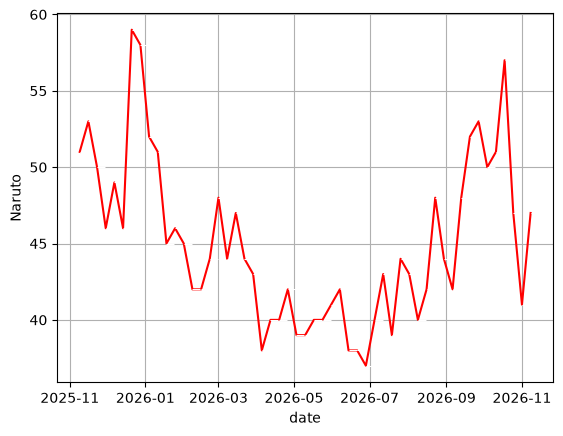

In [160]:
sns.lineplot(data=df_anime , x = df_anime.index , y = 'Naruto' , markers="*" , marker = True , color = 'Red')
plt.grid(True)

In [161]:
print(df_tech.shape)
print(df_tech.info())
print(df_tech.isnull().sum())
print(df_tech.duplicated().sum())
print(df_tech.describe())

(53, 4)
<class 'pandas.DataFrame'>
DatetimeIndex: 53 entries, 2025-11-09 to 2026-11-08
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Python      53 non-null     int64
 1   Java        53 non-null     int64
 2   JavaScript  53 non-null     int64
 3   isPartial   53 non-null     bool 
dtypes: bool(1), int64(3)
memory usage: 1.7 KB
None
Python        0
Java          0
JavaScript    0
isPartial     0
dtype: int64
2
           Python       Java  JavaScript
count   53.000000  53.000000   53.000000
mean    69.433962  52.358491    9.056604
std     11.728515   7.356563    2.545094
min     45.000000  37.000000    4.000000
25%     62.000000  47.000000    8.000000
50%     68.000000  51.000000    9.000000
75%     80.000000  57.000000   10.000000
max    100.000000  71.000000   15.000000


In [162]:
df_tech = df_tech.drop(
    columns=['isPartial'],
    errors='ignore'
)

In [163]:
df_tech[['Python', 'Java', 'JavaScript']].mean()

Python        69.433962
Java          52.358491
JavaScript     9.056604
dtype: float64

In [164]:
df_tech = df_tech.reset_index()
df_tech.head()


,date,Python,Java,JavaScript
0,2025-11-09,89,71,14
1,2025-11-16,87,64,13
2,2025-11-23,84,64,13
3,2025-11-30,89,63,14
4,2025-12-07,90,67,14


### Which Month has python with maximum interest

In [165]:
df_tech.iloc[df_tech['Python'].idxmax() , [0 ,1]]

date      2026-02-08 00:00:00
Python                    100
Name: 13, dtype: object

In [166]:
df_anime = df_anime.reset_index()
df_anime.drop('isPartial' , axis = 1 , inplace=True)

In [167]:
df_anime.iloc[: , :].mean()

date            2026-05-10 00:00:00
Naruto                     45.09434
One Piece                 38.339623
Demon Slayer              20.377358
dtype: object

In [168]:
anime_by_region = pytrend.interest_by_region()

In [169]:
anime_by_region = anime_by_region.reset_index()

In [170]:
anime_by_region.head(6)

,geoName,Naruto,One Piece,Demon Slayer
0,Andaman and Nicobar Islands,40,39,21
1,Andhra Pradesh,48,32,20
2,Arunachal Pradesh,43,36,21
3,Assam,48,32,20
4,Bihar,49,32,19
5,Chandigarh,39,38,23


In [171]:
anime_related_query = pytrend.related_queries()

In [172]:
anime_related_query

{'Naruto': {'top':                           query  value
  0              naruto shippuden    100
  1                naruto episode     92
  2                  anime naruto     55
  3                         anime     54
  4               naruto in hindi     45
  5                naruto drawing     28
  6                       drawing     28
  7               naruto season 1     21
  8                        sasuke     20
  9                  naruto photo     19
  10                 naruto video     17
  11                       hinata     17
  12                naruto hinata     17
  13             naruto wallpaper     16
  14                       boruto     16
  15              naruto episodes     15
  16                  naruto game     13
  17                 naruto movie     13
  18                      kakashi     12
  19                       itachi     11
  20  naruto ultimate ninja storm     10
  21            naruto characters     10
  22                 naruto watch     10

In [173]:
pytrend.related_topics()

{}

In [174]:
pytrend.suggestions('Naruto')

[{'mid': '/m/01hryy', 'title': 'Naruto', 'type': 'Manga series'},
 {'mid': '/m/0b4cxjq',
  'title': 'Naruto: Shippuden',
  'type': 'Animated series'},
 {'mid': '/g/11b7dyzby8', 'title': 'jutsu', 'type': 'Topic'},
 {'mid': '/m/02sp46', 'title': 'Naruto Uzumaki', 'type': 'Naruto character'},
 {'mid': '/g/11bwd2xbf0', 'title': 'Naruto', 'type': 'TV series'}]

## Visualization :-

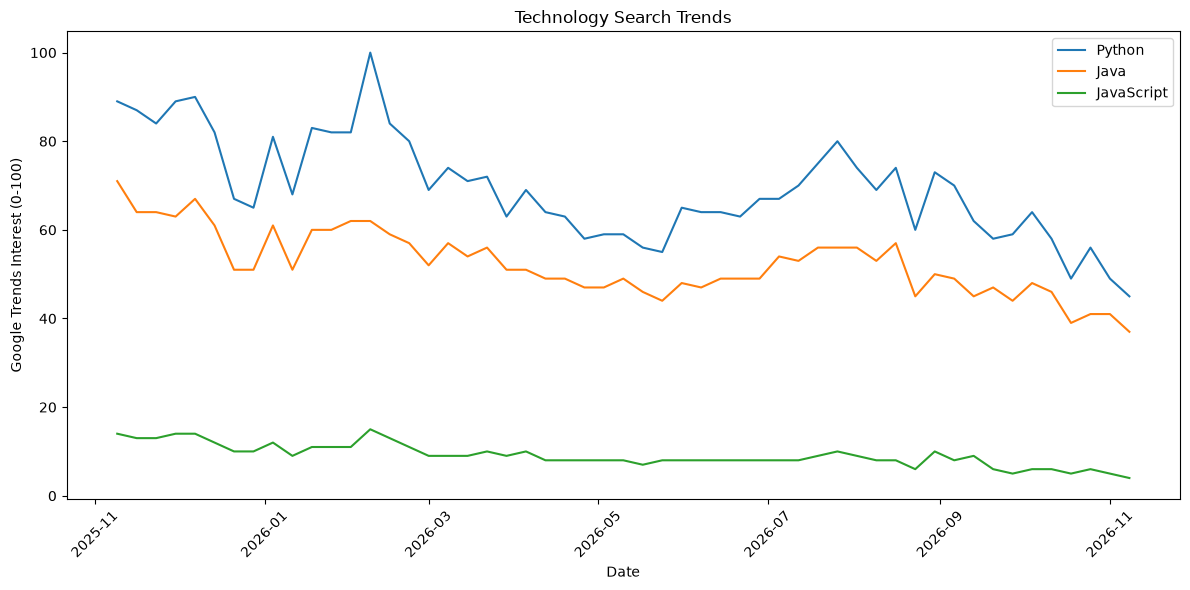

In [175]:
plt.figure(figsize=(12, 6))

for col in ['Python', 'Java', 'JavaScript']:
    plt.plot(df_tech['date'], df_tech[col], label=col)

plt.title('Technology Search Trends')
plt.xlabel('Date')
plt.ylabel('Google Trends Interest (0-100)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

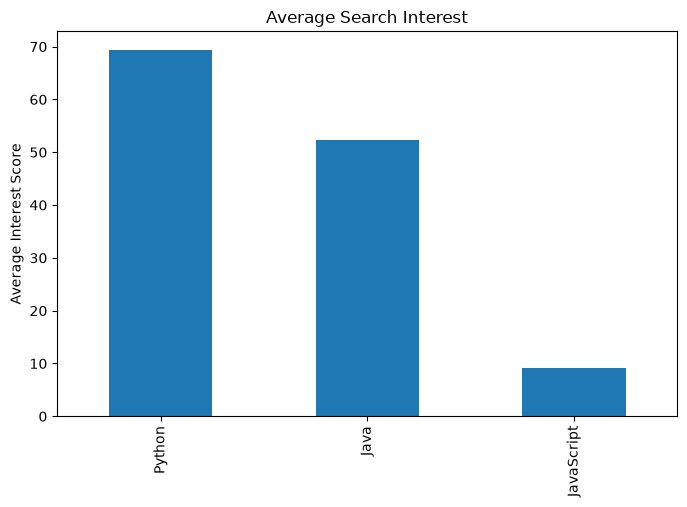

In [176]:
avg = df_tech[
    ['Python', 'Java', 'JavaScript']
].mean()

avg.plot(kind='bar', figsize=(8, 5))

plt.title('Average Search Interest')
plt.ylabel('Average Interest Score')
plt.show()

<Axes: >

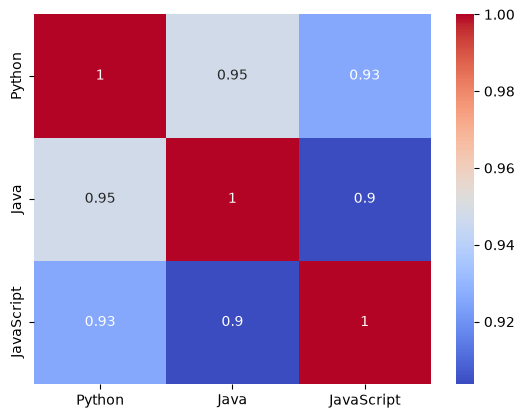

In [177]:
sns.heatmap(df_tech.corr(numeric_only=True), annot=True , cmap='coolwarm')

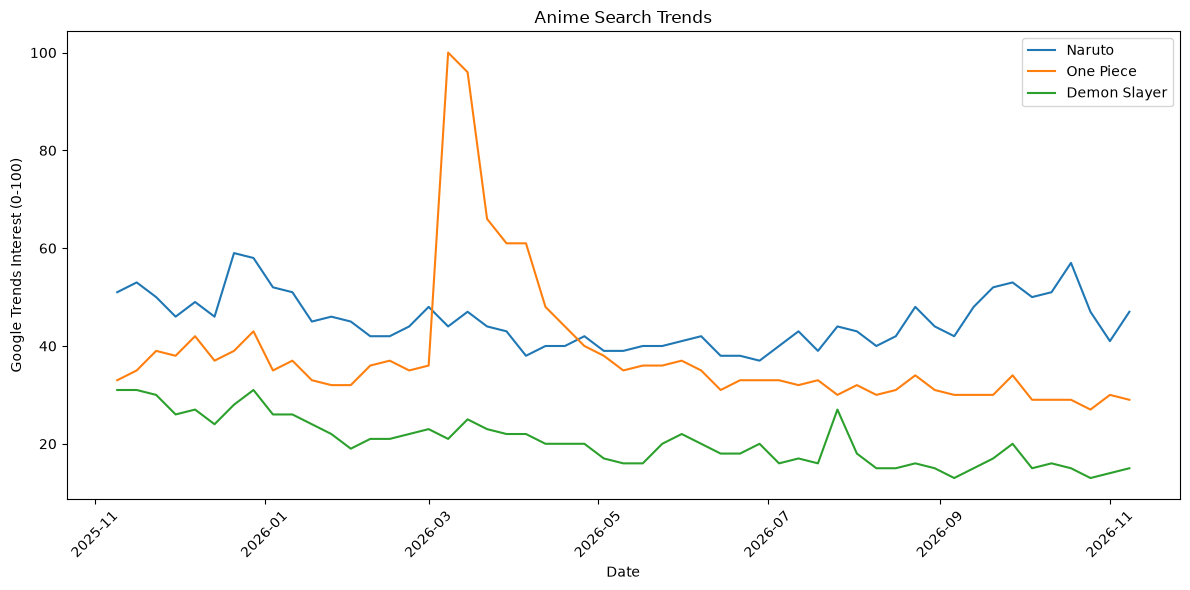

In [178]:
plt.figure(figsize=(12, 6))

for col in ['Naruto' , 'One Piece' , 'Demon Slayer']:
    plt.plot(df_anime['date'], df_anime[col], label=col)

plt.title('Anime Search Trends')
plt.xlabel('Date')
plt.ylabel('Google Trends Interest (0-100)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

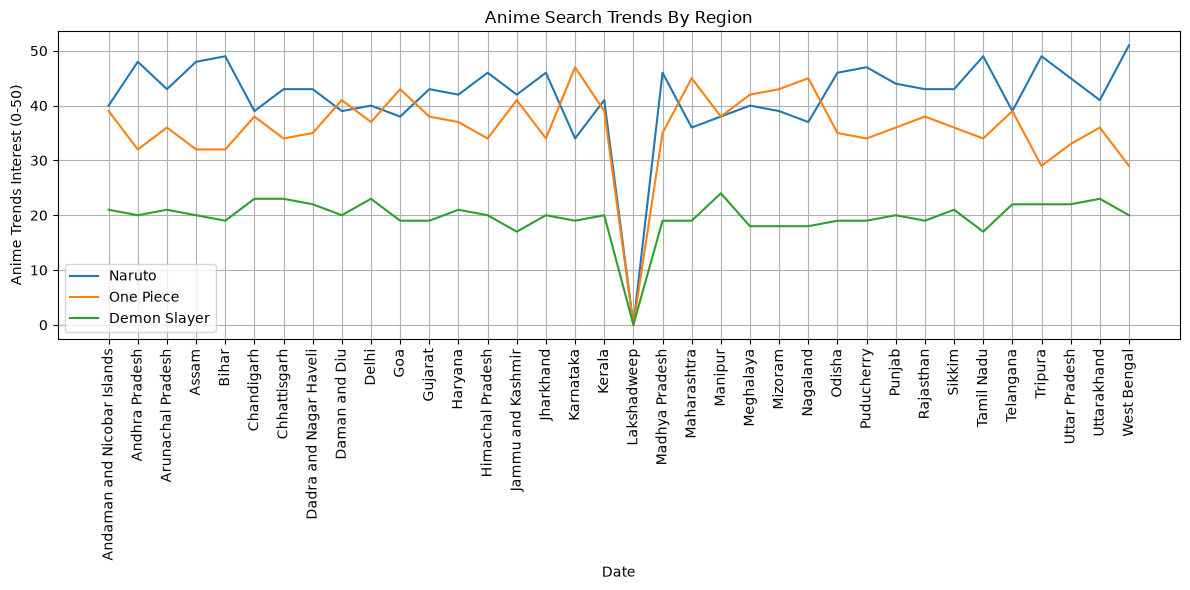

In [179]:
plt.figure(figsize=(12, 6))

for col in ['Naruto' , 'One Piece' , 'Demon Slayer']:
    plt.plot(anime_by_region['geoName'], anime_by_region[col], label=col)

plt.title('Anime Search Trends By Region')
plt.xlabel('Date')
plt.ylabel('Anime Trends Interest (0-50)')
plt.legend()
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [180]:
anime_by_region.describe()

,Naruto,One Piece,Demon Slayer
count,36.000000,36.000000,36.000000
mean,41.583333,36.000000,19.638889
std,8.233642,7.532785,3.803403
min,0.000000,0.000000,0.000000
25%,39.000000,34.000000,19.000000
50%,43.000000,36.000000,20.000000
75%,46.000000,39.000000,21.250000
max,51.000000,47.000000,24.000000


In [181]:
anime_by_region.sort_values(by='Naruto' , ascending=False).head(10)

,geoName,Naruto,One Piece,Demon Slayer
35,West Bengal,51,29,20
32,Tripura,49,29,22
4,Bihar,49,32,19
30,Tamil Nadu,49,34,17
3,Assam,48,32,20
1,Andhra Pradesh,48,32,20
26,Puducherry,47,34,19
19,Madhya Pradesh,46,35,19
25,Odisha,46,35,19
13,Himachal Pradesh,46,34,20
